# Học deep learning với dữ liệu chữ số viết tay MNIST

Notebook này dạy từng bước: dữ liệu ảnh dưới dạng mảng số, mô hình baseline, mạng nơ-ron nhiều lớp (MLP) bằng scikit-learn và Keras, mạng tích chập (CNN) bằng Keras, và cách phân tích lỗi của mô hình phân loại ảnh.

Dữ liệu: 70.000 ảnh xám kích thước 28 x 28 pixel, mỗi ảnh là một chữ số từ 0 đến 9. Có 60.000 ảnh train và 10.000 ảnh test, đã chia sẵn. Mỗi pixel có giá trị từ 0 (đen) đến 255 (trắng). Nguồn: MNIST của LeCun, Cortes và Burges.

Chuẩn bị:
1. Đặt file data9.npz cùng thư mục với notebook. File .npz là định dạng nén của numpy, chứa 4 mảng: X_train, y_train, X_test, y_test.
2. Cài thư viện nếu chưa có: pip install numpy pandas matplotlib scikit-learn tensorflow
3. Các bước dùng Keras (từ bước 10) cần tensorflow. Trên CPU, mỗi bước huấn luyện mất khoảng 1 đến 3 phút. Kết quả của mạng nơ-ron có thể lệch vài phần nghìn so với kết quả mong đợi vì khác máy và khác phiên bản thư viện.

Cách làm: đọc phần giải thích, viết code vào ô trống, chạy bằng Shift + Enter, rồi so sánh với kết quả mong đợi. Nếu kết quả khác, đọc lại đề bài và thử lại trước khi xem đáp án.

## Bước 0: Import thư viện

Mục tiêu: nạp các thư viện dùng trong toàn bộ notebook. Ô này đã viết sẵn, bạn chỉ cần chạy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

## Bước 1: Đọc dữ liệu

Mục tiêu: mở file .npz và kiểm tra kích thước các mảng.

Kiến thức: np.load trả về một đối tượng giống dict. data["X_train"] lấy ra mảng tương ứng. X_train có 3 chiều: (số ảnh, chiều cao, chiều rộng).

Kết quả mong đợi: X_train (60000, 28, 28), y_train (60000,), X_test (10000, 28, 28), y_test (10000,). Kiểu dữ liệu uint8, giá trị pixel từ 0 đến 255.

In [2]:
data = np.load('data9.npz')
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
print(X_train.dtype, X_train.min(), X_train.max())

(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
uint8 0 255


## Bước 2: Xem ảnh

Mục tiêu: nhìn tận mắt dữ liệu trước khi huấn luyện.

Kiến thức: plt.imshow(ảnh, cmap="gray") vẽ một mảng 2 chiều thành ảnh xám. Một ảnh chỉ là một bảng 28 x 28 con số.

Kết quả mong đợi: 10 ảnh đầu là các chữ số 5, 0, 4, 1, 9, 2, 1, 3, 1, 4.

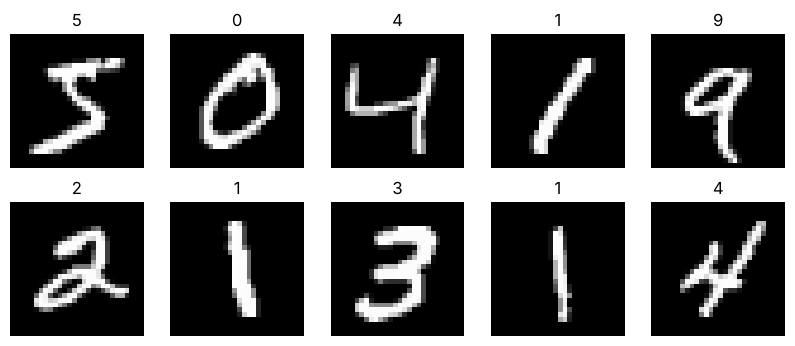

[[  0   0   0   0   0   0   0   3  18  18]
 [  0   0   0  30  36  94 154 170 253 253]
 [  0   0  49 238 253 253 253 253 253 253]
 [  0   0  18 219 253 253 253 253 253 198]
 [  0   0   0  80 156 107 253 253 205  11]
 [  0   0   0   0  14   1 154 253  90   0]
 [  0   0   0   0   0   0 139 253 190   2]
 [  0   0   0   0   0   0  11 190 253  70]
 [  0   0   0   0   0   0   0  35 241 225]
 [  0   0   0   0   0   0   0   0  81 240]]


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i], cmap='gray')
    ax.set_title(y_train[i])
    ax.axis('off')
plt.show()
print(X_train[0][5:15, 5:15])

## Bước 3: Phân phối nhãn

Mục tiêu: kiểm tra các chữ số có số lượng gần bằng nhau không.

Kiến thức: np.bincount đếm số lần xuất hiện của mỗi số nguyên không âm.

Kết quả mong đợi: mỗi chữ số có khoảng 5.400 đến 6.700 ảnh trong tập train. Chữ số 1 nhiều nhất trong tập test (1135 ảnh), nên baseline đoán toàn số 1 đạt khoảng 0,1135.

In [4]:
print('train:', np.bincount(y_train))
print('test :', np.bincount(y_test))
print('Tỷ lệ lớp lớn nhất trong test:', round(np.bincount(y_test).max() / len(y_test), 4))

train: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
test : [ 980 1135 1032 1010  982  892  958 1028  974 1009]
Tỷ lệ lớp lớn nhất trong test: 0.1135


## Bước 4: Duỗi ảnh và chuẩn hóa

Mục tiêu: chuyển mỗi ảnh thành một vector 784 số trong khoảng 0 đến 1.

Kiến thức: mô hình của scikit-learn cần X 2 chiều (số mẫu, số feature). reshape(len, -1) duỗi 28 x 28 thành 784 cột. Chia cho 255 đưa giá trị về khoảng 0 đến 1, giúp mạng nơ-ron học ổn định hơn. Cách duỗi này làm mất thông tin pixel nào nằm cạnh pixel nào, CNN ở bước 12 sẽ giữ lại thông tin đó.

Kết quả mong đợi: X_train_flat có kích thước (60000, 784), giá trị lớn nhất bằng 1,0.

In [5]:
X_train_flat = X_train.reshape(len(X_train), -1) / 255.0
X_test_flat = X_test.reshape(len(X_test), -1) / 255.0
print(X_train_flat.shape, X_test_flat.shape, X_train_flat.max())

(60000, 784) (10000, 784) 1.0


## Bước 5: Baseline và logistic regression

Mục tiêu: có mốc so sánh trước khi dùng mạng nơ-ron.

Kiến thức: DummyClassifier luôn đoán chữ số xuất hiện nhiều nhất. Logistic regression đa lớp học một bộ trọng số 784 số cho mỗi chữ số. Để chạy nhanh, ta chỉ huấn luyện logistic trên 10.000 ảnh đầu. Bước này mất khoảng 30 giây.

Kết quả mong đợi: baseline khoảng 0,1135. Logistic regression trên 10.000 ảnh đạt khoảng 0,905.

In [6]:
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_flat, y_train)
print('Baseline accuracy:', round(dummy.score(X_test_flat, y_test), 4))
logreg = LogisticRegression(max_iter=200)
logreg.fit(X_train_flat[:10000], y_train[:10000])
print('Logistic accuracy:', round(logreg.score(X_test_flat, y_test), 4))

Baseline accuracy: 0.1135


Logistic accuracy: 0.905


## Bước 6: Trọng số của logistic regression

Mục tiêu: hiểu logistic regression "nhìn" gì trong ảnh.

Kiến thức: coef_ có kích thước (10, 784). Reshape mỗi dòng về 28 x 28 và vẽ ra: vùng đỏ là pixel sáng làm tăng xác suất của chữ số đó, vùng xanh làm giảm.

Kết quả mong đợi: mỗi hình trông như một bản mờ của chữ số tương ứng. Ví dụ hình của số 0 có một vòng tròn đỏ với vùng xanh ở giữa.

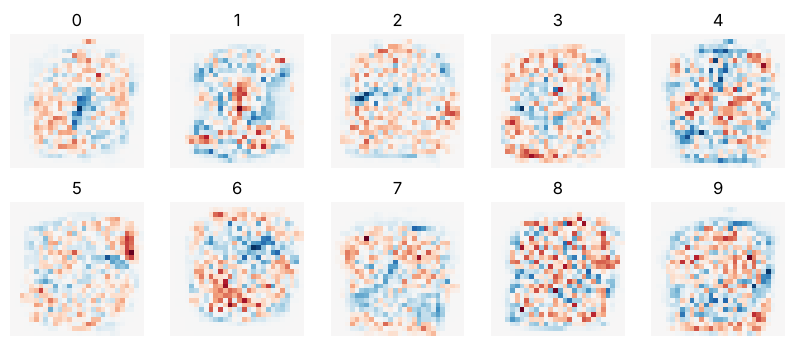

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    w = logreg.coef_[i].reshape(28, 28)
    ax.imshow(w, cmap='RdBu_r', vmin=-np.abs(w).max(), vmax=np.abs(w).max())
    ax.set_title(i)
    ax.axis('off')
plt.show()

## Bước 7: MLP bằng scikit-learn

Mục tiêu: huấn luyện mạng nơ-ron đầu tiên.

Kiến thức: MLP (multi-layer perceptron) gồm lớp vào (784 nơ-ron), các lớp ẩn và lớp ra (10 nơ-ron). Mỗi nơ-ron ẩn tính tổng có trọng số của đầu vào rồi áp dụng hàm kích hoạt ReLU, max(0, x). hidden_layer_sizes=(128,) là một lớp ẩn 128 nơ-ron. early_stopping=True giữ 10% tập train làm validation và dừng khi điểm validation không cải thiện. Bước này mất khoảng 1 đến 2 phút.

Kết quả mong đợi: accuracy khoảng 0,978, chạy hết 30 epoch. Có thể xuất hiện ConvergenceWarning vì mô hình chưa hội tụ hoàn toàn sau 30 epoch, bạn có thể bỏ qua.

In [8]:
mlp = MLPClassifier(hidden_layer_sizes=(128,), max_iter=30, early_stopping=True, random_state=42)
mlp.fit(X_train_flat, y_train)
print('MLP accuracy:', round(mlp.score(X_test_flat, y_test), 4), '| số epoch:', mlp.n_iter_)

MLP accuracy: 0.9784 | số epoch: 30


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


## Bước 8: Đường loss và số tham số

Mục tiêu: xem mạng học thế nào qua từng epoch và đếm số tham số.

Kiến thức: một epoch là một lần đi qua toàn bộ dữ liệu train. loss_curve_ lưu loss trên tập train sau mỗi epoch. validation_scores_ lưu accuracy trên phần validation. Số tham số của một lớp dense = số đầu vào x số nơ-ron + số nơ-ron (bias).

Kết quả mong đợi: loss giảm nhanh trong vài epoch đầu rồi giảm chậm dần. Validation accuracy tăng lên khoảng 0,98 rồi gần như đi ngang. MLP có 101.770 tham số: 784 x 128 + 128 ở lớp ẩn và 128 x 10 + 10 ở lớp ra.

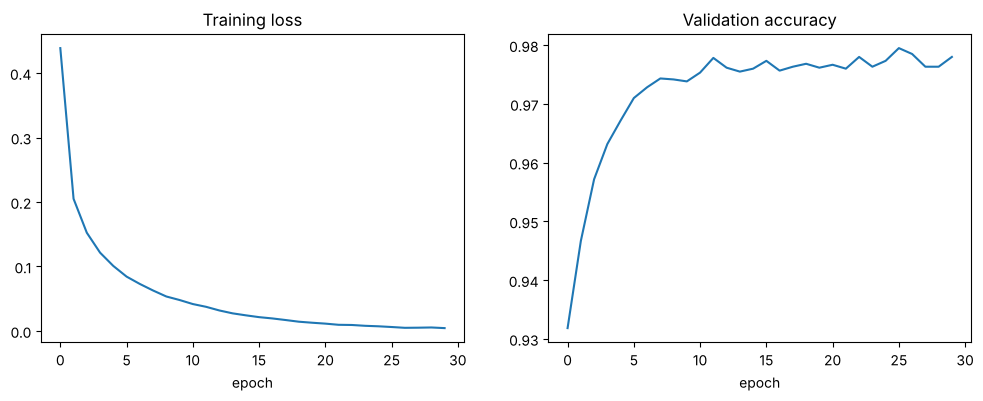

Số tham số của MLP: 101770


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(mlp.loss_curve_)
axes[0].set_title('Training loss')
axes[0].set_xlabel('epoch')
axes[1].plot(mlp.validation_scores_)
axes[1].set_title('Validation accuracy')
axes[1].set_xlabel('epoch')
plt.show()
n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print('Số tham số của MLP:', n_params)

## Bước 9: Confusion matrix và ảnh bị đoán sai

Mục tiêu: tìm cặp chữ số mà mô hình hay nhầm.

Kiến thức: với 10 lớp, confusion matrix có 10 x 10 ô. Để tìm cặp hay nhầm nhất, đặt đường chéo bằng 0 rồi tìm ô lớn nhất. Xem tận mắt các ảnh bị sai thường cho thấy một số ảnh khó ngay cả với người.

Kết quả mong đợi: khoảng 216 ảnh bị sai. Các cặp hay nhầm nhất là thật 4 đoán 9, thật 7 đoán 2 và thật 2 đoán 7 (mỗi cặp khoảng 9 đến 10 ảnh).

Câu hỏi: trong các ảnh bị sai, có ảnh nào bạn cũng không chắc là số gì không?

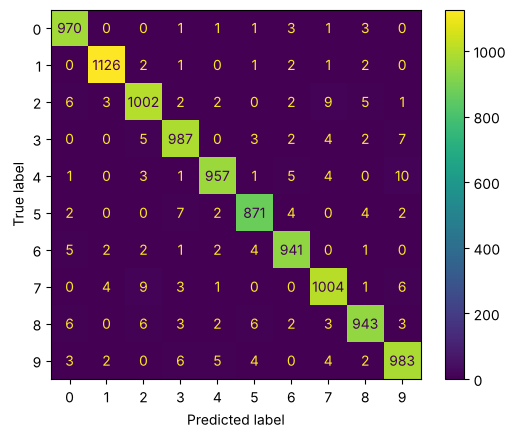

thật 4, đoán 9: 10 ảnh
thật 7, đoán 2: 9 ảnh
thật 2, đoán 7: 9 ảnh
Tổng số ảnh sai: 216


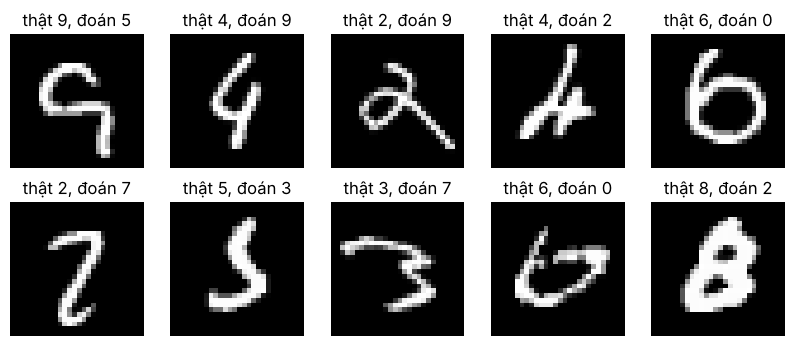

In [10]:
pred_mlp = mlp.predict(X_test_flat)
ConfusionMatrixDisplay.from_predictions(y_test, pred_mlp)
plt.show()
cm = confusion_matrix(y_test, pred_mlp)
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:3], cm.shape))[0]
for t, p in top:
    print(f'thật {t}, đoán {p}: {cm[t, p]} ảnh')

wrong = np.where(pred_mlp != y_test)[0]
print('Tổng số ảnh sai:', len(wrong))
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, i in zip(axes.flat, wrong[:10]):
    ax.imshow(X_test[i], cmap='gray')
    ax.set_title(f'thật {y_test[i]}, đoán {pred_mlp[i]}')
    ax.axis('off')
plt.show()

## Bước 10: MLP bằng Keras

Mục tiêu: xây lại MLP bằng Keras để làm quen với thư viện deep learning.

Kiến thức: Keras xây mạng bằng Sequential gồm các lớp xếp chồng. Dense(128, activation="relu") là lớp ẩn. Dropout(0.2) tắt ngẫu nhiên 20% nơ-ron mỗi bước để giảm overfitting. Lớp cuối Dense(10, activation="softmax") cho 10 xác suất cộng lại bằng 1. compile chọn optimizer (adam), hàm loss (sparse_categorical_crossentropy, dùng khi nhãn là số nguyên 0 đến 9) và chỉ số theo dõi. set_random_seed giúp kết quả gần như lặp lại được.

Kết quả mong đợi: summary cho thấy 101.770 tham số, giống MLP của sklearn. Sau 10 epoch, accuracy trên tập test khoảng 0,977.

In [11]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # ẩn thông báo kỹ thuật của TensorFlow
import tensorflow as tf
from tensorflow import keras
keras.utils.set_random_seed(42)

mlp_k = keras.Sequential([
    keras.Input(shape=(784,)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10, activation='softmax'),
])
mlp_k.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
mlp_k.summary()
hist_mlp = mlp_k.fit(X_train_flat, y_train, epochs=10, batch_size=128, validation_split=0.1, verbose=2)
loss, acc = mlp_k.evaluate(X_test_flat, y_test, verbose=0)
print('Keras MLP test accuracy:', round(acc, 4))

I0000 00:00:1791730879.839784    2188 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791730881.241509    2188 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

...

Epoch 9/10


422/422 - 2s - 4ms/step - accuracy: 0.9793 - loss: 0.0671 - val_accuracy: 0.9788 - val_loss: 0.0721


Epoch 10/10


422/422 - 2s - 4ms/step - accuracy: 0.9811 - loss: 0.0633 - val_accuracy: 0.9803 - val_loss: 0.0669


Keras MLP test accuracy: 0.9772


## Bước 11: Đường học của Keras

Mục tiêu: phát hiện overfitting bằng cách so sánh train và validation qua các epoch.

Kiến thức: hist.history là dict chứa loss, accuracy, val_loss và val_accuracy cho mỗi epoch. Nếu loss train tiếp tục giảm mà val_loss đi ngang hoặc tăng, mô hình bắt đầu overfit.

Kết quả mong đợi: accuracy train tăng từ khoảng 0,88 lên khoảng 0,98. val_accuracy epoch cuối khoảng 0,980. val_loss vẫn giảm đến epoch 10, nên chưa thấy overfitting rõ.

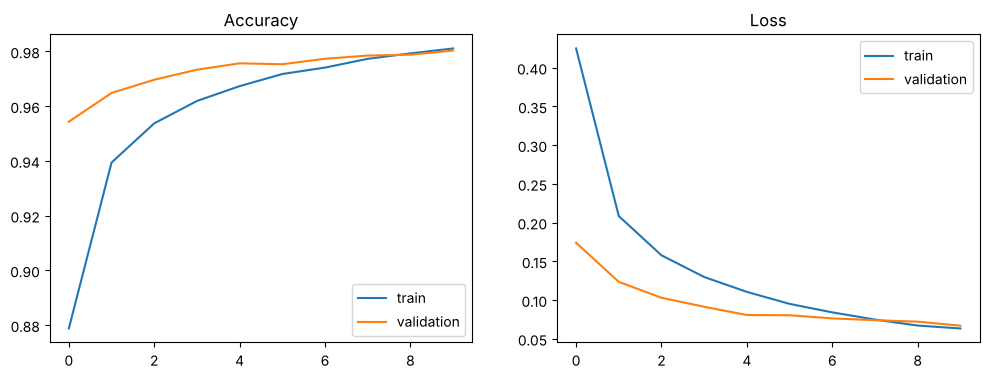

val_accuracy epoch cuối: 0.9803


In [12]:
h = hist_mlp.history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h['accuracy'], label='train')
axes[0].plot(h['val_accuracy'], label='validation')
axes[0].set_title('Accuracy')
axes[0].legend()
axes[1].plot(h['loss'], label='train')
axes[1].plot(h['val_loss'], label='validation')
axes[1].set_title('Loss')
axes[1].legend()
plt.show()
print('val_accuracy epoch cuối:', round(h['val_accuracy'][-1], 4))

## Bước 12: CNN

Mục tiêu: xây mạng tích chập, giữ được cấu trúc không gian của ảnh.

Kiến thức: Conv2D(32, kernel_size=3) trượt 32 bộ lọc 3 x 3 trên ảnh. Mỗi bộ lọc học phát hiện một mẫu nhỏ như nét ngang, nét cong. MaxPooling2D(2) lấy giá trị lớn nhất trong mỗi ô 2 x 2, làm ảnh nhỏ đi một nửa. Flatten duỗi kết quả thành vector trước lớp Dense cuối. CNN cần đầu vào 4 chiều: (số ảnh, cao, rộng, số kênh màu), ảnh xám có 1 kênh. Bước này mất khoảng 2 đến 4 phút trên CPU.

Kết quả mong đợi: X_train_img có kích thước (60000, 28, 28, 1). CNN chỉ có 34.826 tham số. Sau 5 epoch, accuracy trên tập test khoảng 0,988.

In [13]:
X_train_img = X_train[..., np.newaxis] / 255.0
X_test_img = X_test[..., np.newaxis] / 255.0
print(X_train_img.shape)
keras.utils.set_random_seed(42)

cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    keras.layers.Conv2D(32, kernel_size=3, activation='relu'),
    keras.layers.MaxPooling2D(pool_size=2),
    keras.layers.Conv2D(64, kernel_size=3, activation='relu'),
    keras.layers.MaxPooling2D(pool_size=2),
    keras.layers.Flatten(),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(10, activation='softmax'),
])
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn.summary()
hist_cnn = cnn.fit(X_train_img, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=2)
loss, acc = cnn.evaluate(X_test_img, y_test, verbose=0)
print('CNN test accuracy:', round(acc, 4))

(60000, 28, 28, 1)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

...

Epoch 4/5


422/422 - 10s - 25ms/step - accuracy: 0.9780 - loss: 0.0703 - val_accuracy: 0.9875 - val_loss: 0.0429


Epoch 5/5


422/422 - 10s - 25ms/step - accuracy: 0.9804 - loss: 0.0631 - val_accuracy: 0.9890 - val_loss: 0.0382


CNN test accuracy: 0.9876


## Bước 13: Bộ lọc và feature map của CNN

Mục tiêu: xem lớp tích chập đầu tiên "thấy" gì trong một ảnh.

Kiến thức: feature map là kết quả khi một bộ lọc trượt qua ảnh. Có thể tạo một mô hình con trả về đầu ra của lớp Conv2D đầu tiên bằng keras.Model(inputs=cnn.inputs, outputs=cnn.layers[0].output).

Kết quả mong đợi: 16 feature map đầu tiên của ảnh số 7. Một số map sáng ở nét ngang phía trên, một số sáng ở nét chéo, một số sáng ở viền.

(1, 26, 26, 32)


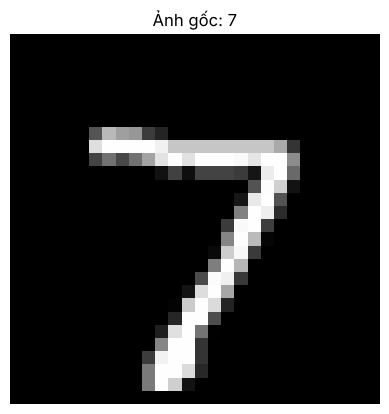

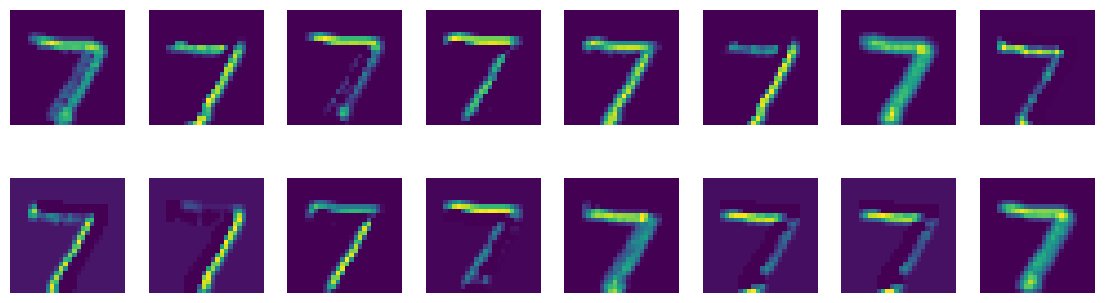

In [14]:
feat_model = keras.Model(inputs=cnn.inputs, outputs=cnn.layers[0].output)
maps = feat_model.predict(X_test_img[:1], verbose=0)
print(maps.shape)
plt.imshow(X_test[0], cmap='gray')
plt.title(f'Ảnh gốc: {y_test[0]}')
plt.axis('off')
plt.show()
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[0, :, :, i], cmap='viridis')
    ax.axis('off')
plt.show()

## Bước 14: Bảng so sánh các mô hình

Mục tiêu: so sánh accuracy, số ảnh sai và số tham số của mọi mô hình.

Kiến thức: model.count_params() trả về số tham số của mô hình Keras. Số ảnh sai = 10000 x (1 - accuracy).

Kết quả mong đợi: CNN đứng đầu với accuracy khoảng 0,988 và khoảng 124 ảnh sai, dùng 34.826 tham số. MLP sklearn khoảng 216 ảnh sai và MLP Keras khoảng 228 ảnh sai, cả hai dùng 101.770 tham số. Logistic sai khoảng 950 ảnh.

Câu hỏi: CNN có ít tham số hơn MLP Keras mà vẫn chính xác hơn. Vì sao? Gợi ý: một bộ lọc 3 x 3 được dùng lại ở mọi vị trí trong ảnh.

In [15]:
rows = [
    {'Mô hình': 'Baseline', 'accuracy': dummy.score(X_test_flat, y_test), 'tham số': 0},
    {'Mô hình': 'Logistic (10k ảnh)', 'accuracy': logreg.score(X_test_flat, y_test), 'tham số': logreg.coef_.size + logreg.intercept_.size},
    {'Mô hình': 'MLP sklearn', 'accuracy': mlp.score(X_test_flat, y_test), 'tham số': n_params},
    {'Mô hình': 'MLP Keras', 'accuracy': accuracy_score(y_test, np.argmax(mlp_k.predict(X_test_flat, verbose=0), axis=1)), 'tham số': mlp_k.count_params()},
    {'Mô hình': 'CNN Keras', 'accuracy': accuracy_score(y_test, np.argmax(cnn.predict(X_test_img, verbose=0), axis=1)), 'tham số': cnn.count_params()},
]
table = pd.DataFrame(rows)
table['số ảnh sai'] = ((1 - table['accuracy']) * len(y_test)).round().astype(int)
table['accuracy'] = table['accuracy'].round(4)
print(table.to_string())

              Mô hình  accuracy  tham số  số ảnh sai
0            Baseline    0.1135        0        8865
1  Logistic (10k ảnh)    0.9050     7850         950
2         MLP sklearn    0.9784   101770         216
3           MLP Keras    0.9772   101770         228
4           CNN Keras    0.9876    34826         124


## Bước 15: Tự thử nghiệm

Không có code mẫu ở bước này. Hãy tự chọn ít nhất hai việc sau:

1. Thêm keras.layers.BatchNormalization() sau mỗi lớp Conv2D và huấn luyện lại CNN. Accuracy và thời gian huấn luyện thay đổi thế nào?
2. Huấn luyện MLP Keras 30 epoch thay vì 10, rồi vẽ đường học. Bạn có thấy overfitting không? Thử thêm keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True).
3. Tự vẽ một chữ số bằng Paint (nền đen, nét trắng, 28 x 28 pixel), đọc bằng plt.imread và cho CNN dự đoán. Mô hình có đoán đúng không?
4. Viết ba câu tiếng Anh so sánh MLP và CNN dựa trên bảng ở bước 14. Ví dụ: "The CNN reduced the number of misclassified test images from ... to ... while using fewer parameters."
